# Exercise 3: Regularisation and Generalisation

This experiment compares dropout and data augmentation with an unchanged CNN baseline. Dropout and augmentation are tested independently; a combined run is included as an additional condition.

## 1. Experimental approach

The CNN uses Conv(3,32), Conv(32,64), and Linear(4096,10). The controlled conditions are Baseline, Dropout alone, and Augmentation alone. An additional combined Dropout + Augmentation run is reported separately from the two single-intervention comparisons.

Dropout with probability 0.5 is applied to flattened features before the output layer. Augmentation uses RandomCrop(32, padding=4) and RandomHorizontalFlip(0.5) on training images only. All conditions use final-epoch models; no test result is used for selection.

In [1]:
import json
import random
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import Markdown, display
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
ARTIFACT_DIR = PROJECT_ROOT / "artifacts" / "exercise_3"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR = PROJECT_ROOT / "data"
EX2_RESULTS_PATH = PROJECT_ROOT / "artifacts" / "exercise_2" / "results.json"
if not EX2_RESULTS_PATH.exists():
    raise FileNotFoundError("Run notebooks/Exercise_2_CNN.ipynb first; its results.json is required for Exercise 3.")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SEEDS = [42, 43, 44]
SPLIT_SEED = 42
BATCH_SIZE = 64
EPOCHS = 20
LEARNING_RATE = 1e-3
DROPOUT_PROBABILITY = 0.5
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

if DEVICE.type == "cpu":
    torch.set_num_threads(min(4, __import__("os").cpu_count() or 1))
print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: CUDA is unavailable; Exercise 3 will run on CPU.")
print("Seeds:", SEEDS, "| Split seed:", SPLIT_SEED, "| Batch size:", BATCH_SIZE,
      "| Epochs:", EPOCHS, "| Learning rate:", LEARNING_RATE)
ex2_results = json.loads(EX2_RESULTS_PATH.read_text(encoding="utf-8"))


Python: D:\AI ML\AI-ML-assessment-cifar10-project\.venv\Scripts\python.exe
PyTorch: 2.14.1+cu126
CUDA available: True
Device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
Seeds: [42, 43, 44] | Split seed: 42 | Batch size: 64 | Epochs: 20 | Learning rate: 0.001


## 2. Training and validation partitions

The fixed split uses `torch.randperm(50_000, generator=torch.Generator().manual_seed(42))`: the first 45,000 indices are training data and the remaining 5,000 are validation data. A clean training dataset supplies validation and evaluation images. A separate augmented training dataset is used only for augmentation conditions. The official test partition is loaded after all 12 final models have finished training.

In [2]:
download = not (DATA_DIR / "cifar-10-batches-py").exists()
clean_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])
augmentation_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])
clean_source = datasets.CIFAR10(
    root=str(DATA_DIR), train=True, download=download, transform=clean_transform
)
augmented_source = datasets.CIFAR10(
    root=str(DATA_DIR), train=True, download=False, transform=augmentation_transform
)
assert len(clean_source) == 50_000 and len(augmented_source) == 50_000
split_indices = torch.randperm(
    50_000, generator=torch.Generator().manual_seed(SPLIT_SEED)
).tolist()
train_indices, val_indices = split_indices[:45_000], split_indices[45_000:]
np.savez(ARTIFACT_DIR / "split_indices.npz", train=train_indices, validation=val_indices)
loader_args = {"batch_size": BATCH_SIZE, "num_workers": 0, "pin_memory": DEVICE.type == "cuda"}
train_eval_loader = DataLoader(Subset(clean_source, train_indices), shuffle=False, **loader_args)
val_loader = DataLoader(Subset(clean_source, val_indices), shuffle=False, **loader_args)

def make_train_loader(seed, augmentation=False):
    source = augmented_source if augmentation else clean_source
    return DataLoader(
        Subset(source, train_indices), shuffle=True,
        generator=torch.Generator().manual_seed(seed), **loader_args,
    )

print(f"Training: {len(train_indices):,}; validation: {len(val_indices):,}")
print("CIFAR-10 download needed:", download)


Training: 45,000; validation: 5,000
CIFAR-10 download needed: False


### Training-image augmentation example

The bottom row shows one random crop-and-flip realization for each original training image.

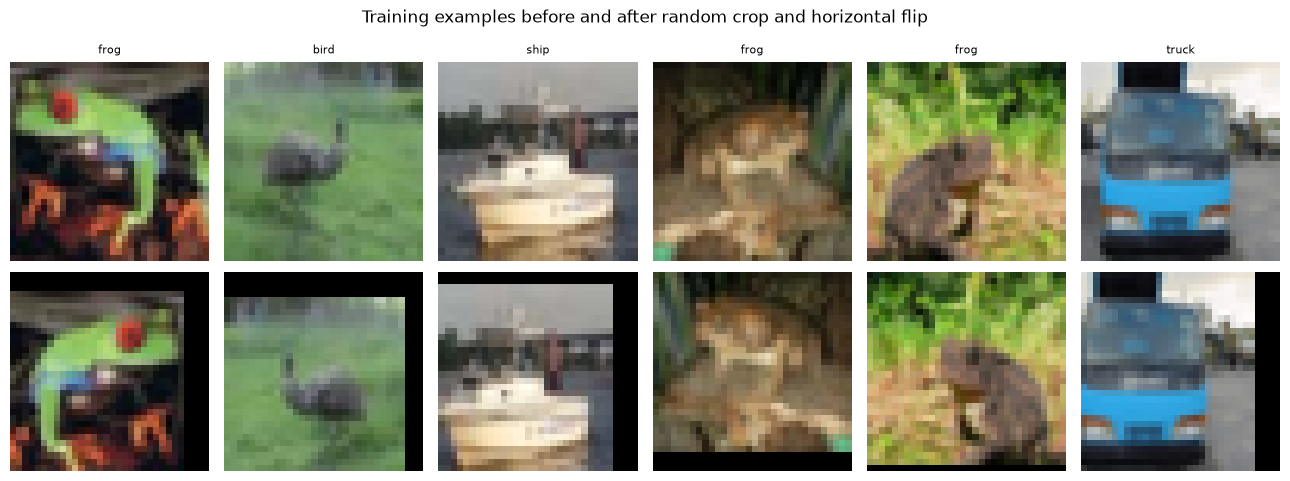

In [3]:
example_indices = train_indices[:6]
mean_tensor = torch.tensor(CIFAR_MEAN).view(3, 1, 1)
std_tensor = torch.tensor(CIFAR_STD).view(3, 1, 1)
fig, axes = plt.subplots(2, 6, figsize=(13, 5))
for column, index in enumerate(example_indices):
    original, label = clean_source[index]
    augmented, augmented_label = augmented_source[index]
    assert label == augmented_label
    for row, image in enumerate((original, augmented)):
        rgb = (image * std_tensor + mean_tensor).clamp(0, 1).permute(1, 2, 0).numpy()
        axes[row, column].imshow(rgb)
        axes[row, column].axis("off")
    axes[0, column].set_title(clean_source.classes[label], fontsize=8)
axes[0, 0].set_ylabel("Original", fontsize=10)
axes[1, 0].set_ylabel("Augmented", fontsize=10)
fig.suptitle("Training examples before and after random crop and horizontal flip")
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "augmentation_examples.png", dpi=160)
plt.show()
plt.close(fig)


## 3. CNN and dropout placement

The learned layers are the same in all conditions: two convolutional layers and a fully connected output layer, for 60,362 trainable parameters. Dropout has no trainable parameters and is applied after flattening only when enabled.

In [4]:
class CIFAR10CNN(nn.Module):
    def __init__(self, dropout_probability=0.0):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2)
        self.flatten = nn.Flatten()
        self.dropout = nn.Dropout(dropout_probability)
        self.fc = nn.Linear(64 * 8 * 8, 10)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        return self.fc(self.dropout(self.flatten(x)))

initial_weights_by_seed = {}
for seed in SEEDS:
    set_seed(seed)
    initial_model = CIFAR10CNN(dropout_probability=0.0)
    parameters = sum(parameter.numel() for parameter in initial_model.parameters() if parameter.requires_grad)
    assert parameters == 60_362, parameters
    initial_weights_by_seed[seed] = {
        name: value.detach().clone() for name, value in initial_model.state_dict().items()
    }
print("Trainable parameters in each condition:", f"{parameters:,}")
print("A single seed-specific initial state is shared by all four conditions for that seed.")


Trainable parameters in each condition: 60,362
A single seed-specific initial state is shared by all four conditions for that seed.


## 4. Training procedure

The primary comparison is Baseline versus Dropout alone versus Augmentation alone. The combined condition is an additional run. Each condition trains from the same seed-specific initial weights with Adam, learning rate 0.001, batch size 64, and 20 epochs. There is no scheduler, weight decay, tuning, or early stopping. Training uses a dedicated shuffled-loader generator; validation and clean training evaluation use deterministic images.

In [5]:
criterion = nn.CrossEntropyLoss()
CONDITIONS = [
    {"name": "Baseline", "key": "baseline", "dropout": 0.0, "augmentation": False, "primary": True},
    {"name": "Dropout", "key": "dropout", "dropout": DROPOUT_PROBABILITY, "augmentation": False, "primary": True},
    {"name": "Augmentation", "key": "augmentation", "dropout": 0.0, "augmentation": True, "primary": True},
    {"name": "Dropout + Augmentation (additional combined run)", "key": "dropout_augmentation", "dropout": DROPOUT_PROBABILITY, "augmentation": True, "primary": False},
]

def epoch_metrics(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    loss_sum, correct, count = 0.0, 0, 0
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for images, labels in loader:
            try:
                images = images.to(DEVICE, non_blocking=True)
                labels = labels.to(DEVICE, non_blocking=True)
                if training:
                    optimizer.zero_grad(set_to_none=True)
                logits = model(images)
                loss = criterion(logits, labels)
                if training:
                    loss.backward()
                    optimizer.step()
                count += labels.size(0)
                loss_sum += loss.item() * labels.size(0)
                correct += (logits.argmax(1) == labels).sum().item()
            except torch.cuda.OutOfMemoryError as exc:
                if training:
                    optimizer.zero_grad(set_to_none=True)
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()
                raise RuntimeError("CUDA out of memory. Stop without retry or configuration changes.") from exc
    return {"loss": loss_sum / count, "accuracy": correct / count}

trained_models = {}
run_results = []

for seed in SEEDS:
    for condition in CONDITIONS:
        set_seed(seed)
        model = CIFAR10CNN(condition["dropout"]).to(DEVICE)
        model.load_state_dict(initial_weights_by_seed[seed])
        parameter_count = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
        assert parameter_count == 60_362, (condition["name"], seed, parameter_count)
        optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=0.0)
        train_loader = make_train_loader(seed, condition["augmentation"])
        history = {key: [] for key in ("train_loss", "train_accuracy", "val_loss", "val_accuracy")}
        started = time.perf_counter()
        for epoch in range(1, EPOCHS + 1):
            train = epoch_metrics(model, train_loader, optimizer)
            validation = epoch_metrics(model, val_loader)
            history["train_loss"].append(train["loss"])
            history["train_accuracy"].append(train["accuracy"])
            history["val_loss"].append(validation["loss"])
            history["val_accuracy"].append(validation["accuracy"])
            print(
                f"{condition['name']} | seed {seed} | epoch {epoch:02d}/{EPOCHS} | "
                f"train loss {train['loss']:.4f}, accuracy {train['accuracy']:.4f} | "
                f"validation loss {validation['loss']:.4f}, accuracy {validation['accuracy']:.4f}",
                flush=True,
            )
        training_seconds = time.perf_counter() - started
        train_eval = epoch_metrics(model, train_eval_loader)
        validation_eval = epoch_metrics(model, val_loader)
        key = (condition["key"], seed)
        trained_models[key] = model
        run_results.append({
            "condition": condition["name"],
            "condition_key": condition["key"],
            "primary_comparison": condition["primary"],
            "seed": seed,
            "trainable_parameters": parameter_count,
            "training_seconds": training_seconds,
            "history": history,
            "train": train_eval,
            "validation": validation_eval,
        })
        print(
            f"{condition['name']} | seed {seed} | clean eval train accuracy {train_eval['accuracy']:.4f} | "
            f"validation accuracy {validation_eval['accuracy']:.4f} | training time {training_seconds:.1f}s",
            flush=True,
        )
        if condition["key"] == "baseline" and seed == 42:
            reference = ex2_results["final_epoch"]["metrics"]
            baseline_differences = {
                "train_accuracy": train_eval["accuracy"] - reference["train"]["accuracy"],
                "validation_accuracy": validation_eval["accuracy"] - reference["validation"]["accuracy"],
            }
            print("Exercise 2 baseline seed-42 train/validation differences:", baseline_differences)
            if max(abs(value) for value in baseline_differences.values()) > 0.0001:
                print("WARNING: Exercise 3 seed-42 train/validation baseline differs from Exercise 2 by more than 0.0001.")

print(f"Training complete: {len(run_results)} final-epoch models; the official test set has not been loaded.")


Baseline | seed 42 | epoch 01/20 | train loss 1.3196, accuracy 0.5347 | validation loss 1.0738, accuracy 0.6226


Baseline | seed 42 | epoch 02/20 | train loss 0.9764, accuracy 0.6604 | validation loss 0.9738, accuracy 0.6640


Baseline | seed 42 | epoch 03/20 | train loss 0.8476, accuracy 0.7063 | validation loss 0.8985, accuracy 0.6908


Baseline | seed 42 | epoch 04/20 | train loss 0.7583, accuracy 0.7392 | validation loss 0.8850, accuracy 0.6964


Baseline | seed 42 | epoch 05/20 | train loss 0.6918, accuracy 0.7626 | validation loss 0.8843, accuracy 0.7056


Baseline | seed 42 | epoch 06/20 | train loss 0.6389, accuracy 0.7816 | validation loss 0.8441, accuracy 0.7144


... (244 outputs left out)

Dropout + Augmentation (additional combined run) | seed 44 | epoch 19/20 | train loss 0.9237, accuracy 0.6768 | validation loss 0.7672, accuracy 0.7264


Dropout + Augmentation (additional combined run) | seed 44 | epoch 20/20 | train loss 0.9196, accuracy 0.6807 | validation loss 0.7873, accuracy 0.7184


Dropout + Augmentation (additional combined run) | seed 44 | clean eval train accuracy 0.7468 | validation accuracy 0.7184 | training time 365.7s


Training complete: 12 final-epoch models; the official test set has not been loaded.


## 5. Learning curves

The learning curves use seed 42 for all four conditions. Online training curves include dropout and/or random augmentation when enabled; validation always uses the clean, deterministic images. The final comparisons below use clean evaluation-mode training metrics.

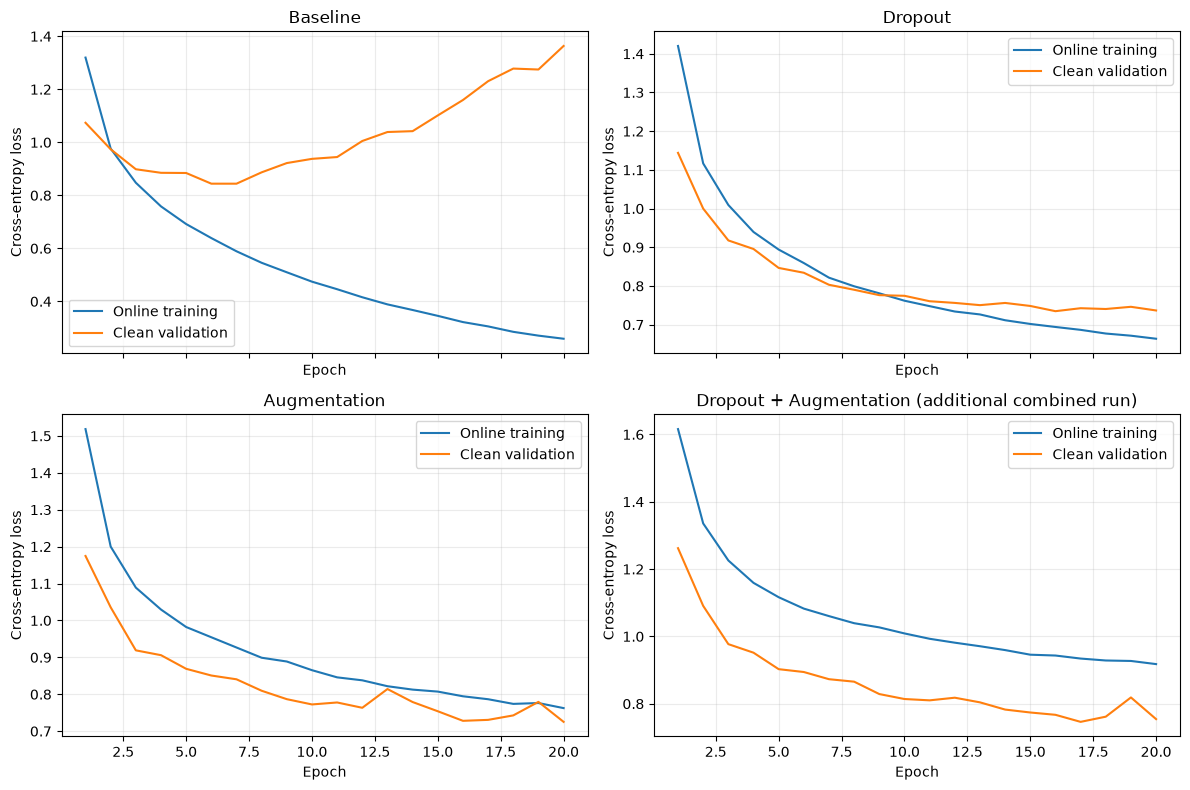

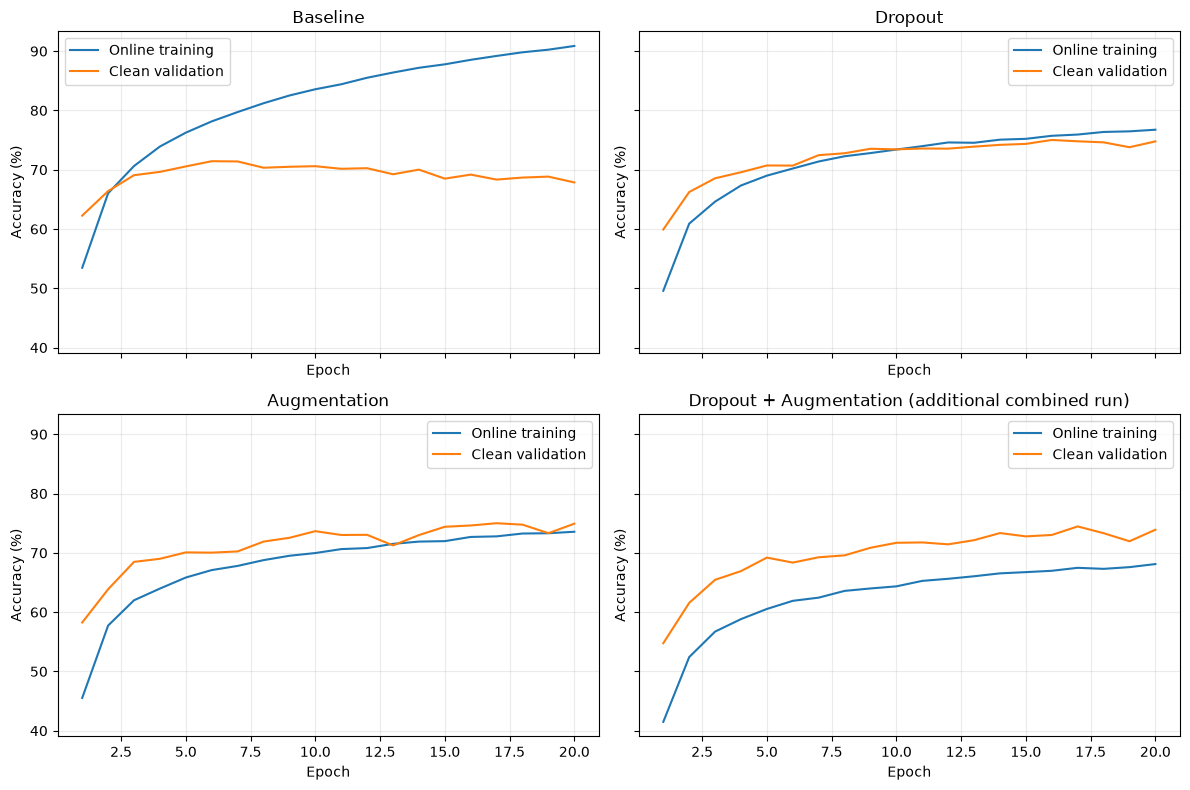

In [6]:
seed42_histories = {
    condition["name"]: next(run["history"] for run in run_results
                            if run["condition_key"] == condition["key"] and run["seed"] == 42)
    for condition in CONDITIONS
}
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
for ax, condition in zip(axes.flat, CONDITIONS):
    history = seed42_histories[condition["name"]]
    epochs = range(1, EPOCHS + 1)
    ax.plot(epochs, history["train_loss"], label="Online training")
    ax.plot(epochs, history["val_loss"], label="Clean validation")
    ax.set(title=condition["name"], xlabel="Epoch", ylabel="Cross-entropy loss")
    ax.legend(); ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "learning_curves.png", dpi=160)
plt.show()
plt.close(fig)
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
for ax, condition in zip(axes.flat, CONDITIONS):
    history = seed42_histories[condition["name"]]
    epochs = range(1, EPOCHS + 1)
    ax.plot(epochs, 100 * np.array(history["train_accuracy"]), label="Online training")
    ax.plot(epochs, 100 * np.array(history["val_accuracy"]), label="Clean validation")
    ax.set(title=condition["name"], xlabel="Epoch", ylabel="Accuracy (%)")
    ax.legend(); ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "accuracy_curves.png", dpi=160)
plt.show()
plt.close(fig)


## 6. Final training and test comparison

After all 12 final models have completed training, load the official 10,000-image test partition once and evaluate each model once. The test data is not used to choose an epoch or modify a condition. The Exercise 2 early-stopped model is included as a validation-loss-selected reference only, outside the controlled comparison.

Baseline | seed 42 | official test accuracy 0.6850; test loss 1.3832


Dropout | seed 42 | official test accuracy 0.7445; test loss 0.7382


Augmentation | seed 42 | official test accuracy 0.7563; test loss 0.7188


Dropout + Augmentation (additional combined run) | seed 42 | official test accuracy 0.7388; test loss 0.7525


Baseline | seed 43 | official test accuracy 0.6855; test loss 1.3170


Dropout | seed 43 | official test accuracy 0.7389; test loss 0.7628


... (5 outputs left out)

Dropout + Augmentation (additional combined run) | seed 44 | official test accuracy 0.7281; test loss 0.7884
Exercise 3 baseline seed-42 matches Exercise 2 to 0.0001: True
Actual Exercise 3 minus Exercise 2 baseline differences: {'train_accuracy': 0.0, 'validation_accuracy': 0.0, 'test_accuracy': 0.0}
Exercise 2 CNN reference metrics:


,Reference,selection,train_accuracy,validation_accuracy,test_loss,test_accuracy
0,Exercise 2 final-epoch CNN,Final epoch,0.920889,0.6786,1.383230,0.6850
1,"Baseline (retrained in Ex 3, seed 42)",Cross-check,0.920889,0.6786,1.383230,0.6850
2,Exercise 2 early-stopped CNN,Validation-loss-selected,NaN,NaN,0.859613,0.7143


Exercise 3 mean and standard deviation across seeds:


,condition,condition_key,primary_comparison,parameters,train_accuracy_mean,train_accuracy_std,validation_accuracy_mean,validation_accuracy_std,test_accuracy_mean,test_accuracy_std,train_test_gap_pp_mean,train_test_gap_pp_std,train_loss_mean,train_loss_std,test_loss_mean,test_loss_std
0,Baseline,baseline,True,60362,0.9187,0.0062,0.6869,0.0072,0.6881,0.0049,23.0622,0.4912,0.2321,0.0206,1.3650,0.0420
1,Dropout,dropout,True,60362,0.8381,0.0094,0.7453,0.0049,0.7374,0.0079,10.0633,0.1936,0.4849,0.0220,0.7660,0.0296
2,Augmentation,augmentation,True,60362,0.7729,0.0082,0.7427,0.0083,0.7463,0.0098,2.6548,0.3277,0.6637,0.0259,0.7472,0.0276
3,Dropout + Augmentation (additional combined run),dropout_augmentation,False,60362,0.7497,0.0056,0.7266,0.0109,0.7315,0.0064,1.8230,0.0797,0.7259,0.0166,0.7741,0.0190


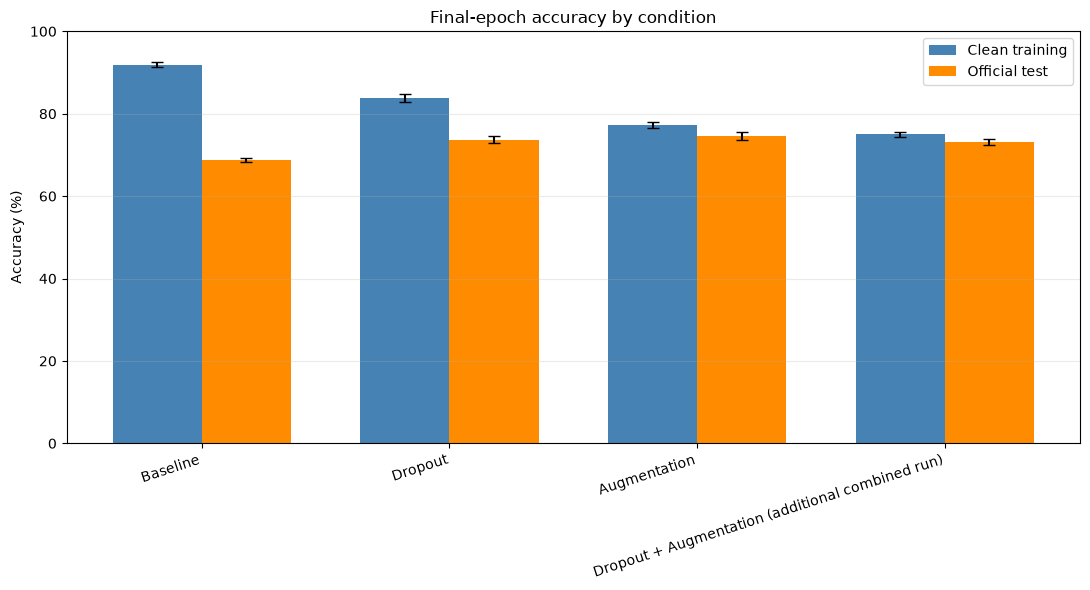

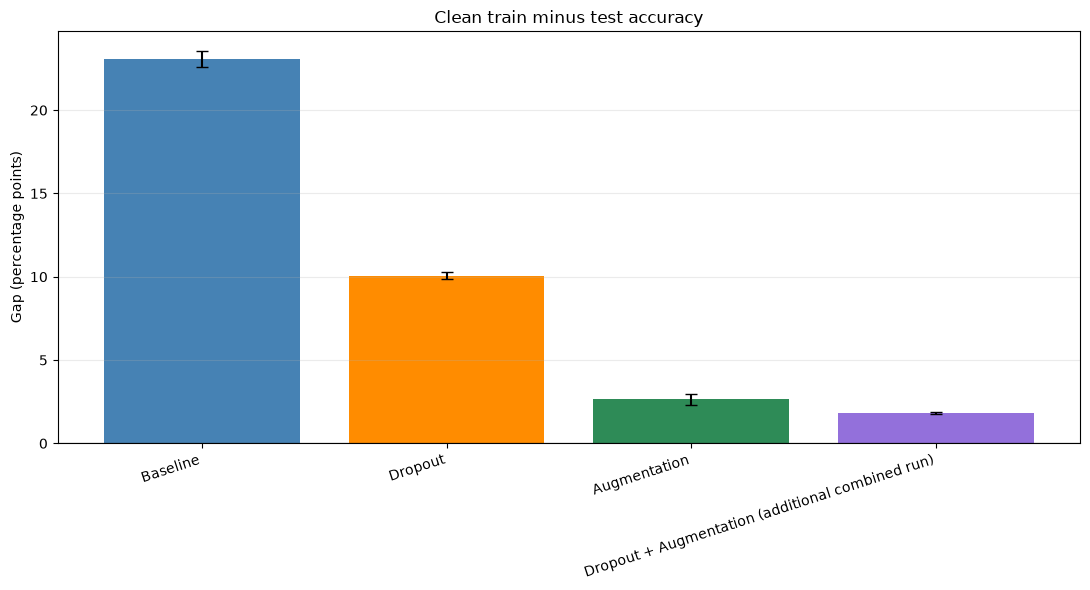

In [7]:
test_dataset = datasets.CIFAR10(
    root=str(DATA_DIR), train=False, download=download, transform=clean_transform
)
assert len(test_dataset) == 10_000
test_loader = DataLoader(test_dataset, shuffle=False, **loader_args)
for run in run_results:
    key = (run["condition_key"], run["seed"])
    run["test"] = epoch_metrics(trained_models[key], test_loader)
    print(
        f"{run['condition']} | seed {run['seed']} | official test accuracy "
        f"{run['test']['accuracy']:.4f}; test loss {run['test']['loss']:.4f}"
    )

baseline_reference = ex2_results["final_epoch"]["metrics"]
baseline_seed42 = next(run for run in run_results if run["condition_key"] == "baseline" and run["seed"] == 42)
baseline_differences = {
    "train_accuracy": baseline_seed42["train"]["accuracy"] - baseline_reference["train"]["accuracy"],
    "validation_accuracy": baseline_seed42["validation"]["accuracy"] - baseline_reference["validation"]["accuracy"],
    "test_accuracy": baseline_seed42["test"]["accuracy"] - baseline_reference["test"]["accuracy"],
}
baseline_matches_ex2 = all(abs(value) <= 0.0001 for value in baseline_differences.values())
print("Exercise 3 baseline seed-42 matches Exercise 2 to 0.0001:", baseline_matches_ex2)
print("Actual Exercise 3 minus Exercise 2 baseline differences:", baseline_differences)
if not baseline_matches_ex2:
    print("WARNING: Exercise 3 seed-42 baseline differs from Exercise 2 by more than 0.0001.")

run_frame = pd.DataFrame([
    {
        "condition": run["condition"], "condition_key": run["condition_key"],
        "primary_comparison": run["primary_comparison"], "seed": run["seed"],
        "parameters": run["trainable_parameters"], "training_seconds": run["training_seconds"],
        "train_accuracy": run["train"]["accuracy"], "validation_accuracy": run["validation"]["accuracy"],
        "test_accuracy": run["test"]["accuracy"],
        "train_test_gap_pp": 100 * (run["train"]["accuracy"] - run["test"]["accuracy"]),
        "train_loss": run["train"]["loss"], "test_loss": run["test"]["loss"],
    }
    for run in run_results
])
run_frame.to_csv(ARTIFACT_DIR / "regularisation_runs.csv", index=False)
metrics = ["train_accuracy", "validation_accuracy", "test_accuracy", "train_test_gap_pp", "train_loss", "test_loss"]
aggregate_rows = []
for condition in CONDITIONS:
    subset = run_frame[run_frame["condition_key"] == condition["key"]]
    row = {
        "condition": condition["name"], "condition_key": condition["key"],
        "primary_comparison": condition["primary"], "parameters": 60_362,
    }
    for metric in metrics:
        values = subset[metric].astype(float)
        row[f"{metric}_mean"] = float(values.mean())
        row[f"{metric}_std"] = float(values.std(ddof=1))
    aggregate_rows.append(row)
comparison = pd.DataFrame(aggregate_rows)
comparison.to_csv(ARTIFACT_DIR / "regularisation_comparison.csv", index=False)

reference_early = ex2_results["best_validation_loss"]
reference_rows = pd.DataFrame([
    {"Reference": "Exercise 2 final-epoch CNN", "selection": "Final epoch",
     "train_accuracy": baseline_reference["train"]["accuracy"], "validation_accuracy": baseline_reference["validation"]["accuracy"],
     "test_loss": baseline_reference["test"]["loss"], "test_accuracy": baseline_reference["test"]["accuracy"]},
    {"Reference": "Baseline (retrained in Ex 3, seed 42)", "selection": "Cross-check",
     "train_accuracy": baseline_seed42["train"]["accuracy"], "validation_accuracy": baseline_seed42["validation"]["accuracy"],
     "test_loss": baseline_seed42["test"]["loss"], "test_accuracy": baseline_seed42["test"]["accuracy"]},
    {"Reference": "Exercise 2 early-stopped CNN", "selection": "Validation-loss-selected",
     "train_accuracy": np.nan, "validation_accuracy": np.nan,
     "test_loss": reference_early["test"]["loss"], "test_accuracy": reference_early["test"]["accuracy"]},
])
print("Exercise 2 CNN reference metrics:")
display(reference_rows)
print("Exercise 3 mean and standard deviation across seeds:")
display(comparison.round(4))

results_payload = {
    "seed_list": SEEDS, "split_seed": SPLIT_SEED,
    "split_method": "torch.randperm(50000), seed 42; first 45000 training",
    "device": str(DEVICE), "torch_version": torch.__version__,
    "epochs": EPOCHS, "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE,
    "optimizer": "Adam", "weight_decay": 0.0, "selection": "final epoch",
    "normalisation": {"mean": CIFAR_MEAN, "std": CIFAR_STD},
    "augmentation": {"crop": "RandomCrop(32, padding=4)", "horizontal_flip_probability": 0.5},
    "dropout_probability": DROPOUT_PROBABILITY,
    "parameters_per_condition": 60_362,
    "baseline_cross_check": {"matches_to_0.0001": baseline_matches_ex2, "differences": baseline_differences},
    "exercise_2_final_baseline_reference": baseline_reference,
    "exercise_2_early_stopped_reference": {
        "epoch": reference_early["epoch"], "selection_metric": "validation_loss",
        "test": reference_early["test"], "part_of_controlled_comparison": False,
    },
    "runs": run_results,
    "aggregated": aggregate_rows,
}
(ARTIFACT_DIR / "results.json").write_text(json.dumps(results_payload, indent=2), encoding="utf-8")

conditions_order = [condition["key"] for condition in CONDITIONS]
condition_labels = [condition["name"] for condition in CONDITIONS]
positions = np.arange(len(CONDITIONS))
fig, ax = plt.subplots(figsize=(11, 6))
train_means = comparison["train_accuracy_mean"].to_numpy() * 100
train_stds = comparison["train_accuracy_std"].to_numpy() * 100
test_means = comparison["test_accuracy_mean"].to_numpy() * 100
test_stds = comparison["test_accuracy_std"].to_numpy() * 100
ax.bar(positions - 0.18, train_means, 0.36, yerr=train_stds, capsize=4, label="Clean training", color="steelblue")
ax.bar(positions + 0.18, test_means, 0.36, yerr=test_stds, capsize=4, label="Official test", color="darkorange")
ax.set_xticks(positions, condition_labels, rotation=18, ha="right")
ax.set(title="Final-epoch accuracy by condition", ylabel="Accuracy (%)", ylim=(0, 100))
ax.legend(); ax.grid(axis="y", alpha=0.25); fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "accuracy_comparison.png", dpi=160)
plt.show(); plt.close(fig)
fig, ax = plt.subplots(figsize=(11, 6))
gap_means = comparison["train_test_gap_pp_mean"].to_numpy()
gap_stds = comparison["train_test_gap_pp_std"].to_numpy()
ax.bar(positions, gap_means, yerr=gap_stds, capsize=4, color=["steelblue", "darkorange", "seagreen", "mediumpurple"])
ax.set_xticks(positions, condition_labels, rotation=18, ha="right")
ax.set(title="Clean train minus test accuracy", ylabel="Gap (percentage points)")
ax.axhline(0, color="black", linewidth=0.8); ax.grid(axis="y", alpha=0.25); fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "train_test_gap.png", dpi=160)
plt.show(); plt.close(fig)


## 7. Discussion

In [8]:
baseline_row = comparison.set_index("condition_key").loc["baseline"]
def mean_std_text(mean, std, unit="pp"):
    return f"{mean:+.2f} {unit} ? {std:.2f} {unit}"

delta_lines = []
delta_statistics = {}
for condition in ("dropout", "augmentation", "dropout_augmentation"):
    condition_runs = {run["seed"]: run for run in run_results if run["condition_key"] == condition}
    baseline_runs = {run["seed"]: run for run in run_results if run["condition_key"] == "baseline"}
    test_changes = [100 * (condition_runs[seed]["test"]["accuracy"] - baseline_runs[seed]["test"]["accuracy"]) for seed in SEEDS]
    gap_changes = [
        100 * ((condition_runs[seed]["train"]["accuracy"] - condition_runs[seed]["test"]["accuracy"])
               - (baseline_runs[seed]["train"]["accuracy"] - baseline_runs[seed]["test"]["accuracy"]))
        for seed in SEEDS
    ]
    test_mean, test_std = float(np.mean(test_changes)), float(np.std(test_changes, ddof=1))
    gap_mean, gap_std = float(np.mean(gap_changes)), float(np.std(gap_changes, ddof=1))
    display_name = next(item["name"] for item in CONDITIONS if item["key"] == condition)
    delta_statistics[condition] = {"test_accuracy_change_pp_mean": test_mean, "test_accuracy_change_pp_std": test_std,
                                   "train_test_gap_change_pp_mean": gap_mean, "train_test_gap_change_pp_std": gap_std}
    delta_lines.append(
        f"- **{display_name}:** test accuracy changed by {mean_std_text(test_mean, test_std)} versus the retrained baseline; "
        f"the train-to-test gap changed by {mean_std_text(gap_mean, gap_std)}."
    )

dropout_values = comparison.set_index("condition_key").loc["dropout"]
augmentation_values = comparison.set_index("condition_key").loc["augmentation"]
technique_difference = abs(dropout_values["test_accuracy_mean"] - augmentation_values["test_accuracy_mean"]) * 100
combined_seed_sd = float(np.hypot(dropout_values["test_accuracy_std"], augmentation_values["test_accuracy_std"]) * 100)
technique_verdict = "exceeds" if technique_difference > combined_seed_sd else "does not exceed"
combined = comparison.set_index("condition_key").loc["dropout_augmentation"]
early = results_payload["exercise_2_early_stopped_reference"]
base_test = baseline_row["test_accuracy_mean"]
early_test = early["test"]["accuracy"]
combined_test = combined["test_accuracy_mean"]
combined_gap = combined["train_test_gap_pp_mean"]

discussion = f"""### Results and interpretation

The baseline was retrained in Exercise 3 on the GPU using the shared settings. Its seed-42 train, validation, and test accuracies {('match' if baseline_matches_ex2 else 'do not match')} the Exercise 2 final-epoch baseline to 0.0001. Actual differences (Exercise 3 minus Exercise 2) were {baseline_differences['train_accuracy']:+.6f} for training, {baseline_differences['validation_accuracy']:+.6f} for validation, and {baseline_differences['test_accuracy']:+.6f} for test accuracy. The mean final-epoch baseline test accuracy across seeds was {base_test:.2%}.

{chr(10).join(delta_lines)}

Dropout and augmentation test-accuracy means differed by {technique_difference:.2f} pp, which {technique_verdict} their combined seed standard deviation of {combined_seed_sd:.2f} pp. With three seeds this is a heuristic, not a significance test. The seed standard deviations do not include variation from a different train/validation split.

The additional combined run reached mean test accuracy {combined_test:.2%} and a mean train-to-test gap of {combined_gap:.2f} pp. It is reported separately and is not used to replace the primary single-intervention comparisons.

The Exercise 2 early-stopped CNN is a separate validation-loss-selected reference from epoch {early['epoch']} with test accuracy {early_test:.2%}, compared with {baseline_reference['test']['accuracy']:.2%} for the Exercise 2 final-epoch CNN. Part of this difference is consistent with avoiding later overfitting in the 20-epoch baseline; the early-stopped result is not part of the controlled Exercise 3 comparison.

Dropout can reduce co-adaptation by preventing the output layer from relying too heavily on particular flattened features. Random crops and flips expose the CNN to translated and mirrored training views, encouraging some tolerance to those changes. This experiment treats crop and flip as one pipeline.

Limitations include three seeds, one fixed split, one dropout probability, crop and flip evaluated together, no weight decay, and a 20-epoch budget. Test accuracy is descriptive and did not guide condition selection."""
display(Markdown(discussion))
results_payload["paired_changes_vs_retrained_baseline"] = delta_statistics
results_payload["dropout_vs_augmentation_test_difference"] = {
    "absolute_mean_difference_pp": float(technique_difference),
    "combined_seed_sd_pp": combined_seed_sd,
    "difference_exceeds_combined_seed_sd": bool(technique_difference > combined_seed_sd),
    "interpretation": "heuristic with three seeds",
}
(ARTIFACT_DIR / "results.json").write_text(json.dumps(results_payload, indent=2), encoding="utf-8")
(ARTIFACT_DIR / "measured_findings.md").write_text("# Exercise 3: measured findings\n\n" + discussion + "\n", encoding="utf-8")


### Results and interpretation

The baseline was retrained in Exercise 3 on the GPU using the shared settings. Its seed-42 train, validation, and test accuracies match the Exercise 2 final-epoch baseline to 0.0001. Actual differences (Exercise 3 minus Exercise 2) were +0.000000 for training, +0.000000 for validation, and +0.000000 for test accuracy. The mean final-epoch baseline test accuracy across seeds was 68.81%.

- **Dropout:** test accuracy changed by +4.94 pp ? 1.26 pp versus the retrained baseline; the train-to-test gap changed by -13.00 pp ? 0.57 pp.
- **Augmentation:** test accuracy changed by +5.83 pp ? 1.13 pp versus the retrained baseline; the train-to-test gap changed by -20.41 pp ? 0.76 pp.
- **Dropout + Augmentation (additional combined run):** test accuracy changed by +4.34 pp ? 0.98 pp versus the retrained baseline; the train-to-test gap changed by -21.24 pp ? 0.56 pp.

Dropout and augmentation test-accuracy means differed by 0.89 pp, which does not exceed their combined seed standard deviation of 1.26 pp. With three seeds this is a heuristic, not a significance test. The seed standard deviations do not include variation from a different train/validation split.

The additional combined run reached mean test accuracy 73.15% and a mean train-to-test gap of 1.82 pp. It is reported separately and is not used to replace the primary single-intervention comparisons.

The Exercise 2 early-stopped CNN is a separate validation-loss-selected reference from epoch 7 with test accuracy 71.43%, compared with 68.50% for the Exercise 2 final-epoch CNN. Part of this difference is consistent with avoiding later overfitting in the 20-epoch baseline; the early-stopped result is not part of the controlled Exercise 3 comparison.

Dropout can reduce co-adaptation by preventing the output layer from relying too heavily on particular flattened features. Random crops and flips expose the CNN to translated and mirrored training views, encouraging some tolerance to those changes. This experiment treats crop and flip as one pipeline.

Limitations include three seeds, one fixed split, one dropout probability, crop and flip evaluated together, no weight decay, and a 20-epoch budget. Test accuracy is descriptive and did not guide condition selection.

2309